# 01 · The paper, the device and the data

**Base paper:** C. Akbar, Y. Li, N. Thoti, *"Device-Simulation-Based Machine Learning Technique for the
Characteristic of Line Tunnel Field-Effect Transistors"*, IEEE Access 10, 53098 (2022).

**What the paper does:** simulates a scaled line TFET (SLTFET, Si$_{0.6}$Ge$_{0.4}$ source, n-epitaxy over
source/channel) in 3-D TCAD, varies four device parameters ($L_{ov}$, $t_n$, $t_{ox}$, $WK$), and trains a
**Random Forest Regressor** that maps $(V_G, L_{ov}, t_n, t_{ox}, WK) \rightarrow I_D$. Reported: $R^2 > 99\%$,
error < 1 %, ~99 % less compute than TCAD.

**What this project adds** (one notebook each):

| Notebook | Content |
|---|---|
| **01** (this one) | Device physics, analytical simulator, generate all datasets |
| **02** | Reproduce the paper's RFR baseline, then show where it breaks (subthreshold, SS, extrapolation, data leakage) |
| **03** | Better surrogates: log-target, physics features, XGBoost, **physics-informed neural network** |
| **04** | **Uncertainty** (deep ensembles), **active learning** (fewer simulations), temperature/V_D (PVT) extension |
| **05** | **Explainability** (SHAP), **inverse design** (multi-objective optimisation), interactive explorer |

> **About the data.** The paper used commercial 3-D TCAD. Here the "simulator" is the analytical model in
> `tfet/physics.py` (Kane BTBT + trap-assisted tunnelling, the paper's tunnelling-length formula and Table-1
> ranges), calibrated to the current levels in the paper's figures. Every notebook only calls
> `tfet.dataset.simulate(...)`, so you can swap in real TCAD data later without changing the ML code.

### 🧒 The whole notebook in simple words

A **transistor** is a tiny on/off switch for electricity. A **tunnel transistor (TFET)** is a special switch where
electrons sneak *through* a thin wall (quantum tunnelling) instead of climbing *over* it, so it needs less battery.

This notebook:
1. builds a **fast pretend simulator** of the paper's switch,
2. draws pictures of what each "knob" (device parameter) does,
3. makes **thousands of example switches** (datasets) that later notebooks use to teach a computer.

**Mini-dictionary** (you'll see these words everywhere):

| Word | Simple meaning |
|---|---|
| $V_G$ (gate voltage) | how hard you press the switch (0 to 0.5 V) |
| $V_D$ (drain voltage) | the battery pushing electrons through |
| $I_D$ (drain current) | how much electricity flows through (A/µm) |
| $L_{ov}$ | how big the tunnelling "door" is (nm) |
| $t_n$ | thickness of the thin layer electrons tunnel through (nm) |
| $t_{ox}$ | thickness of the insulator between the gate and the device (nm). Thinner = better control |
| $WK$ | gate work function (eV): how hard the switch is to turn on |
| $I_{ON}$ / $I_{OFF}$ | current when the switch is fully ON / OFF. Want ON big, OFF tiny |
| $SS$ (subthreshold swing) | how *snappy* the switch is: mV of push needed for 10× more current. Smaller = better (normal transistors can't beat 60) |
| $V_{th}$ (threshold voltage) | the push at which we say "it's now ON" |
| **dataset** | a big table of examples: knob settings → curve |

### 🧰 Block: load the tools
**What it does:** loads the Python libraries we need, like opening your toolbox before building.
* `numpy`: maths with lists of numbers · `pandas`: tables (like Excel) · `matplotlib`: drawing graphs
* `from tfet import ...`: loads **our own code** from the `tfet/` folder (the simulator and helpers)
* `NOMINAL` is the "default" switch: the knob settings used when we're not changing that knob.

In [1]:
import sys, time
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tfet import NOMINAL, PARAM_RANGES, PARAM_NAMES, id_vg, figures_of_merit, tunnelling_length
from tfet import dataset

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("nominal device:", NOMINAL)

nominal device: {'L_ov': 5.0, 'WK': 4.4, 't_n': 2.0, 't_ox': 3.0}


## 1. Physics captured by the simulator

* Vertical BTBT through the overlap, tunnelling area $A_{tun} = L_{ov}\cdot 2(W + t_n)$  (paper §II-A)
* Lateral BTBT at the source/channel junction (present even when $L_{ov}\to 0$)
* Tunnelling length $\lambda = \sqrt{\varepsilon_{ns} t_{ox} t_n / \varepsilon_{ox}}$  (paper §II-C)
* Kane generation $\propto F^2 \exp(-B/F)$ with the paper's Si$_{0.6}$Ge$_{0.4}$ value $B = 16.8$ MV/cm
* $WK$ shifts the onset voltage (paper §II-D: higher $WK$ → lower $I_{ON}$)
* Trap-assisted tunnelling (TAT) sets the off-state floor
* Temperature: Varshni band gap + thermally activated TAT (*extension: the paper's future work*)

Below: transfer curves for each parameter swept across its Table-1 range, on log and linear axes
(compare with the paper's Fig. 5).

### 🎛️ Block: turn each knob and watch what happens
**What it does:** for each of the 4 knobs, it builds 6 switches with that knob turned from its minimum to its maximum
(the other knobs stay at default), runs the simulator, and draws each switch's curve.

**How to read the picture:**
* **x-axis** = how hard we press the switch ($V_G$). **y-axis** = how much current flows ($I_D$).
* **Top row** uses a *log scale*: every grid line is **10× more** current. This lets you see tiny OFF currents (1e-14) and big
  ON currents (1e-4) on the same picture.
* **Bottom row** is the normal (linear) scale. Here you only see the ON part; the OFF part looks like zero.
* Each colour is one knob setting (dark = small value, yellow = large value).

**What to notice:** bigger $L_{ov}$ → more current (bigger door). Bigger $WK$ → switch turns on later.
Thicker $t_n$ or $t_{ox}$ → less current (weaker control).

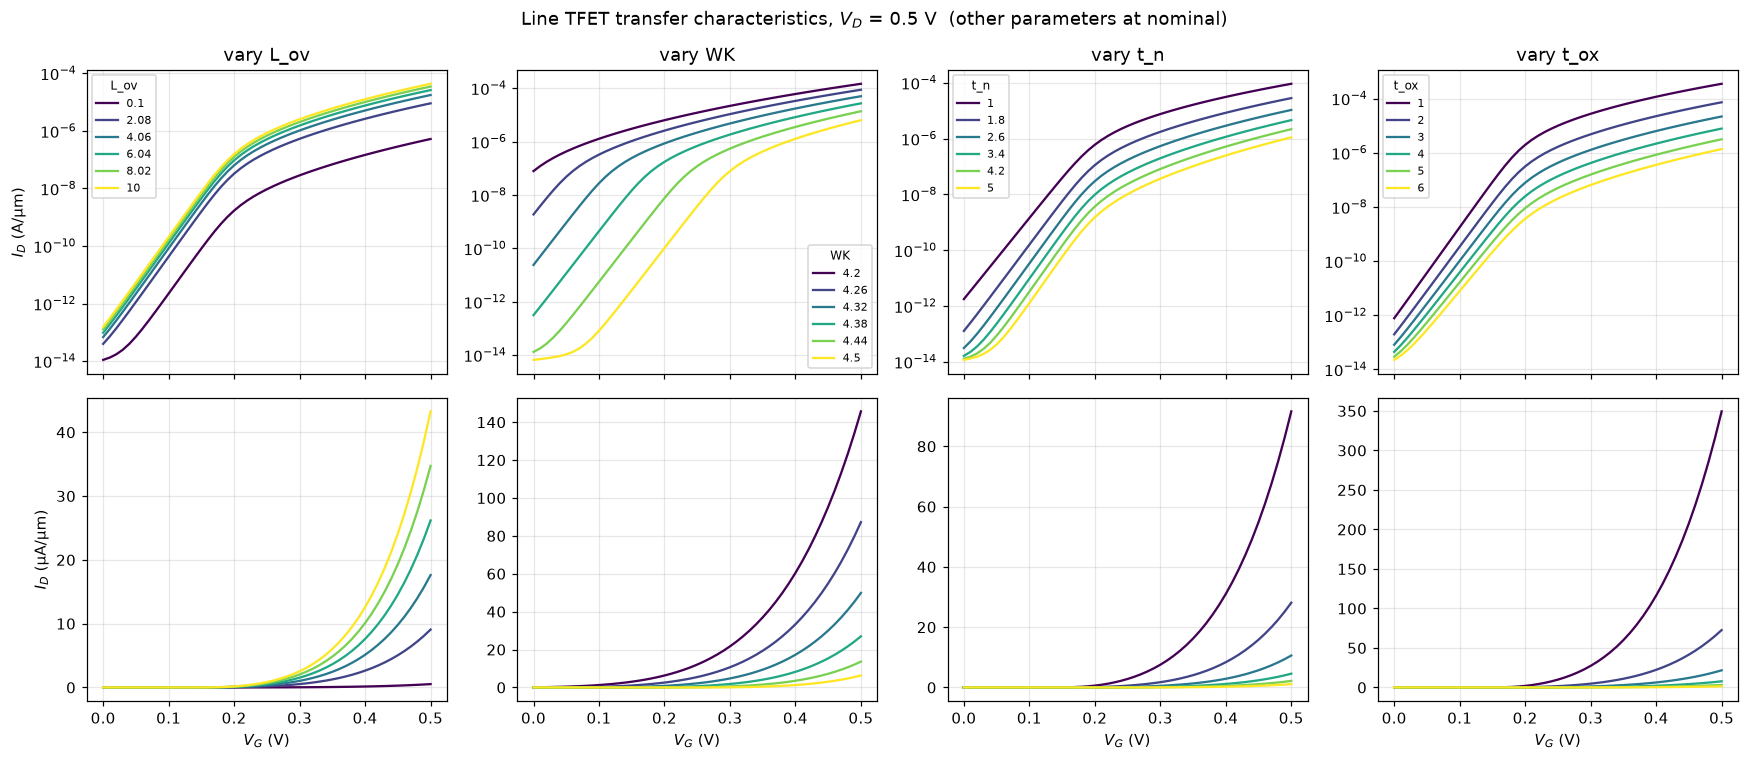

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
for j, (name, (lo, hi)) in enumerate(PARAM_RANGES.items()):
    cmap = plt.get_cmap("viridis")
    for k, v in enumerate(np.linspace(lo, hi, 6)):
        p = dict(NOMINAL, **{name: v})        # default switch, with one knob changed
        V, I = id_vg(p)                       # run the simulator -> V_G sweep and current
        axes[0, j].semilogy(V, I, color=cmap(k / 5), label=f"{v:.3g}")
        axes[1, j].plot(V, I * 1e6, color=cmap(k / 5))
    axes[0, j].set_title(f"vary {name}")
    axes[0, j].legend(fontsize=7, title=name, title_fontsize=8)
    axes[1, j].set_xlabel("$V_G$ (V)")
axes[0, 0].set_ylabel("$I_D$ (A/µm)")
axes[1, 0].set_ylabel("$I_D$ (µA/µm)")
fig.suptitle("Line TFET transfer characteristics, $V_D$ = 0.5 V  (other parameters at nominal)")
fig.tight_layout()
fig.savefig("../figures/01_param_sweeps.png", bbox_inches="tight")

## 2. Drain bias and temperature

Left: the paper's Fig. 8 condition ($V_D$ = 0.5, 0.05, 0.005 V). Right: temperature, which the paper does
not cover. The off current (TAT) rises with temperature and SS degrades, while the BTBT on-current barely moves.
That's the textbook TFET signature.

### 🔋🌡️ Block: change the battery and the temperature
**What it does:** takes the default switch and
* **left:** tries 3 battery strengths ($V_D$ = 0.5, 0.05, 0.005 V), the same test as the paper's Fig. 8;
* **right:** tries 4 temperatures, from cold (250 K ≈ −23 °C) to hot (400 K ≈ 127 °C). The paper didn't test this.

**What to notice:** a weaker battery → less current everywhere. Heat → the OFF current "leaks" more (left end of the curve
rises), but the ON current hardly changes.

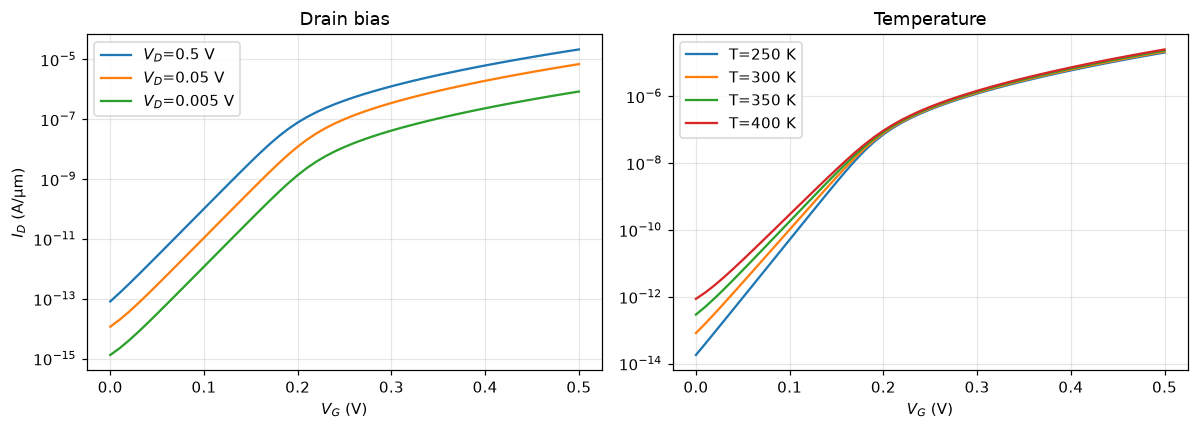

In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
for vd in (0.5, 0.05, 0.005):
    V, I = id_vg(NOMINAL, V_D=vd)
    a.semilogy(V, I, label=f"$V_D$={vd} V")
a.set(title="Drain bias", xlabel="$V_G$ (V)", ylabel="$I_D$ (A/µm)"); a.legend()
for T in (250, 300, 350, 400):
    V, I = id_vg(NOMINAL, T=T)
    b.semilogy(V, I, label=f"T={T} K")
b.set(title="Temperature", xlabel="$V_G$ (V)"); b.legend()
fig.tight_layout()
fig.savefig("../figures/01_bias_temperature.png", bbox_inches="tight")

## 3. Figures of merit across the design space

`tfet.figures_of_merit` extracts $I_{ON}$ ($V_G$ = 0.5 V), $I_{OFF}$ ($V_G$ = 0), $V_{th}$ (constant current
$10^{-10}$ A/µm), $SS_{min}$ and $SS_{avg}$. The paper reports $SS_{min}$ ≈ 29–39 mV/dec (Table 5).

### 📋 Block: make a "report card" for switches
**What it does:** for the default switch and for each knob at its min and max, it measures the switch's **figures of merit**
(the report-card scores: $I_{ON}$, $I_{OFF}$, ON/OFF ratio, $V_{th}$, $SS_{min}$, $SS_{avg}$) and shows them in a table.

`figures_of_merit(V, I)` is our helper that reads a curve and calculates those scores automatically.
A *good* switch has: big `I_on`, tiny `I_off`, huge `on_off`, and small `SS` (around 30 is excellent).

In [4]:
rows = []
for name, (lo, hi) in PARAM_RANGES.items():
    for v in (lo, hi):
        V, I = id_vg(dict(NOMINAL, **{name: v}))
        rows.append({"parameter": name, "value": v, **figures_of_merit(V, I)})
V, I = id_vg(NOMINAL)
rows.insert(0, {"parameter": "nominal", "value": np.nan, **figures_of_merit(V, I)})
fom = pd.DataFrame(rows)                    # turn the list of report cards into a table
fom.style.format({"I_on": "{:.2e}", "I_off": "{:.2e}", "on_off": "{:.1e}", "V_th": "{:.3f}",
                  "SS_min": "{:.1f}", "SS_avg": "{:.1f}", "value": "{:.3g}"})

,parameter,value,I_on,I_off,on_off,V_th,SS_min,SS_avg
0,nominal,nan,2.17e-05,8.17e-14,2.7e+08,0.100,31.6,31.7
1,L_ov,0.1,5.23e-07,1.10e-14,4.8e+07,0.153,31.8,32.4
2,L_ov,10,4.33e-05,1.54e-13,2.8e+08,0.090,31.6,31.7
3,WK,4.2,1.46e-04,7.82e-08,1.9e+03,nan,nan,nan
4,WK,4.5,6.30e-06,6.61e-15,9.5e+08,0.200,31.6,32.5
5,t_n,1,9.16e-05,1.76e-12,5.2e+07,0.060,34.4,34.4
6,t_n,5,1.10e-06,1.17e-14,9.4e+07,0.158,30.1,30.8
7,t_ox,1,3.49e-04,7.78e-13,4.5e+08,0.063,29.7,29.7
8,t_ox,6,1.36e-06,2.25e-14,6.0e+07,0.138,34.5,34.9


Notice that at **WK = 4.2 eV** the device is already on at $V_G$ = 0 (huge $I_{OFF}$, no $V_{th}$). This is why the
paper says a work function of 4.2–4.4 eV "maintains a high ON/OFF ratio" only towards the upper end. It's a
useful design constraint for the inverse-design notebook.

## 4. Generate the datasets

Same four datasets as the paper (§III), plus an extended one:

| file | curves | what varies |
|---|---|---|
| `ds1_one_at_a_time` | 400 | one parameter at a time (100 values each) |
| `ds2_lov_tn` | 200 | $L_{ov}$ and $t_n$ jointly |
| `ds3_drain_bias` | 900 | 300 random devices × $V_D$ ∈ {0.5, 0.05, 0.005} |
| `ds4_all_params` | 2500 | all four parameters (Latin hypercube) |
| `ds5_extended` | 3000 | four parameters + $V_D$ (0.05–0.5 V) + T (250–400 K) |

Each curve has 51 $V_G$ points (0–0.5 V). A 0.5 % multiplicative noise mimics TCAD convergence noise.

### 🏭 Block: build all 5 datasets and save them
**What it does:** this is the "factory".
1. `builders` is a list of 5 recipes. Each recipe decides **which knob settings** to try (`dataset.one_at_a_time`, etc.).
2. For each recipe, `dataset.simulate(...)` runs the simulator on every switch and records its whole curve (51 points).
3. The result is saved as a file in the `data/` folder (`.pkl` = a saved pandas table), so later notebooks can load it
   instead of simulating again.
4. Finally it prints a small table: how many curves, how many rows, and how many seconds each took.

In [5]:
builders = {
    "ds1_one_at_a_time": dataset.one_at_a_time,
    "ds2_lov_tn": dataset.lov_tn_pairs,
    "ds3_drain_bias": dataset.with_drain_bias,
    "ds4_all_params": dataset.all_parameters,
    "ds5_extended": dataset.extended,
}
summary = []
for i, (fname, build) in enumerate(builders.items()):
    t0 = time.perf_counter()
    devices = build()                         # step 1: choose the knob settings
    df = dataset.simulate(devices, seed=i)    # step 2: run the simulator on every switch
    if "varied" in devices:                       # keep the label for dataset 1
        df["varied"] = np.repeat(devices["varied"].values, len(dataset.V_G_SWEEP))
    df.to_pickle(f"../data/{fname}.pkl")      # step 3: save to the data/ folder
    summary.append({"dataset": fname, "curves": df.curve_id.nunique(), "rows": len(df),
                    "seconds": round(time.perf_counter() - t0, 2)})
pd.DataFrame(summary)

,dataset,curves,rows,seconds
0,ds1_one_at_a_time,400,20400,0.08
1,ds2_lov_tn,200,10200,0.04
2,ds3_drain_bias,900,45900,0.19
3,ds4_all_params,2500,127500,0.44
4,ds5_extended,3000,153000,0.51


The paper needed **~5 hours of TCAD per 100 curves**. The analytical simulator makes thousands of curves in
seconds. That's what makes the data-hungry experiments in notebooks 03–05 (ensembles, active learning,
optimisation) practical on a laptop. When you move to TCAD, active learning (notebook 04) shows how to keep the
number of simulations small.

### 👀 Block: peek inside a dataset
**What it does:** loads dataset 4 back from disk and shows its first 5 rows.

Each **row** = one point on one curve. Columns: `curve_id` (which switch), the 4 knob values, `V_D` (battery),
`T` (temperature), `V_G` (how hard we pressed) and `I_D` (the answer: how much current flowed).
One switch = 51 rows (51 different presses from 0 to 0.5 V).

In [6]:
ds4 = pd.read_pickle("../data/ds4_all_params.pkl")
ds4.head()

,curve_id,L_ov,WK,t_n,t_ox,V_D,T,V_G,I_D
0,0,2.285581,4.275212,1.363518,1.854836,0.5,300.0,0.00,3.818989e-09
1,0,2.285581,4.275212,1.363518,1.854836,0.5,300.0,0.01,7.734355e-09
2,0,2.285581,4.275212,1.363518,1.854836,0.5,300.0,0.02,1.615965e-08
3,0,2.285581,4.275212,1.363518,1.854836,0.5,300.0,0.03,3.266966e-08
4,0,2.285581,4.275212,1.363518,1.854836,0.5,300.0,0.04,6.482157e-08


### 🌈 Block: draw 60 random switches
**What it does:** picks the first 60 switches from dataset 4 (all knobs random) and draws their curves together.
This shows how **different** the switches can be. That variety is what the computer has to learn in the next notebooks.

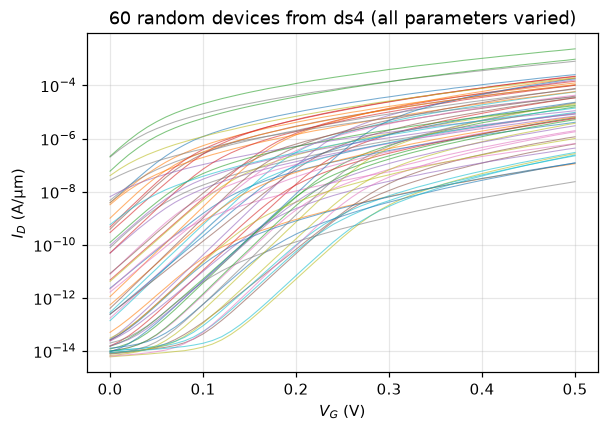

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
for cid in ds4.curve_id.unique()[:60]:
    c = ds4[ds4.curve_id == cid]
    ax.semilogy(c.V_G, c.I_D, lw=0.7, alpha=0.6)
ax.set(title="60 random devices from ds4 (all parameters varied)", xlabel="$V_G$ (V)", ylabel="$I_D$ (A/µm)")
fig.savefig("../figures/01_ds4_sample.png", bbox_inches="tight")